In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn


In [2]:
SEED = 1337

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

FIGURES_DIR = ROOT / "figures"
CHECKPOINT_PATH = ROOT / "checkpoints" / "gpt_char.pt"
CORPUS_PATH = ROOT / "data" / "input.txt"

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

## 1. Recharger le modèle

L'architecture est celle du script 06, recopiée ici avec les
hyperparamètres passés explicitement au lieu de variables globales : c'est
la forme qu'elle prendra dans le projet. Le checkpoint contient la
configuration et le vocabulaire ; sans eux, les poids seuls sont
inutilisables.

In [3]:
class Head(nn.Module):
    """Une tête de self-attention masquée."""

    def __init__(self, n_embd: int, head_size: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, T, _ = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = self.dropout(F.softmax(wei, dim=-1))
        return wei @ self.value(x)


class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées puis projetées."""

    def __init__(self, n_embd: int, n_head: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.heads = nn.ModuleList(Head(n_embd, n_embd // n_head, block_size, dropout) for _ in range(n_head))
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class FeedForward(nn.Module):
    """MLP appliqué à chaque position indépendamment."""

    def __init__(self, n_embd: int, dropout: float) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Block(nn.Module):
    """Bloc Transformer pre-norm : attention puis feed-forward, avec résiduels."""

    def __init__(self, n_embd: int, n_head: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.sa(self.ln1(x))
        return x + self.ffwd(self.ln2(x))


class GPTLanguageModel(nn.Module):
    """GPT caractère, identique au modèle final du script 06."""

    def __init__(self, vocab_size: int, block_size: int, n_embd: int, n_head: int, n_layer: int,
                 dropout: float) -> None:
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """Renvoie les logits `(B, T, vocab_size)`."""
        _, T = idx.shape
        x = self.token_embedding_table(idx) + self.position_embedding_table(torch.arange(T, device=idx.device))
        return self.lm_head(self.ln_f(self.blocks(x)))

In [4]:
if not CHECKPOINT_PATH.exists():
    raise SystemExit(f"{CHECKPOINT_PATH.relative_to(ROOT)} introuvable : exécuter d'abord 06_transformer_pas_a_pas.py")

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
config = checkpoint["config"]
model = GPTLanguageModel(**config).to(device)
model.load_state_dict(checkpoint["model_state"])
model.eval()  # coupe le dropout : on génère, on n'entraîne plus

chars = checkpoint["chars"]
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}


def encode(s: str) -> list[int]:
    """Texte → liste d'indices."""
    return [stoi[c] for c in s]


def decode(ids: list[int]) -> str:
    """Liste d'indices → texte."""
    return "".join(itos[i] for i in ids)


print(f"modèle rechargé : {config}   val loss {checkpoint['val_loss']:.4f}")

modèle rechargé : {'vocab_size': 65, 'block_size': 64, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}   val loss 1.6077


## 2. Ce que prédit le modèle

Donnons-lui un début de réplique et regardons la distribution du caractère
suivant : seulement la **dernière position** des logits nous intéresse.

In [5]:
@torch.no_grad()
def next_char_logits(prompt: str) -> torch.Tensor:
    """Logits du caractère qui suit `prompt` (au plus `block_size` derniers caractères)."""
    idx = torch.tensor([encode(prompt)[-model.block_size :]], device=device)
    return model(idx)[0, -1]


prompt = "ROMEO:\nWhat light through yonder wind"
logits = next_char_logits(prompt)
probs = F.softmax(logits, dim=-1)
top = probs.topk(8)
print(f"après {prompt!r} :")
for p, i in zip(top.values, top.indices):
    print(f"  {itos[i.item()]!r:6} {p.item():.3f}")

après 'ROMEO:\nWhat light through yonder wind' :
  ' '    0.313
  'e'    0.270
  's'    0.178
  ','    0.098
  '.'    0.026
  ';'    0.021
  '\n'   0.018
  'i'    0.013


Le modèle a une préférence nette, mais il laisse de la probabilité à d'autres suites. Toute la question de ce script : **comment choisir** dans
cette distribution, 500 fois de suite.

## 3. Glouton : toujours le plus probable

L'idée naturelle : prendre à chaque pas le caractère le plus probable
(`argmax`). C'est déterministe, et c'est une mauvaise idée pour du texte
libre.

In [6]:
@torch.no_grad()
def generate_with(pick, prompt: str = "\n", n_chars: int = 300) -> str:
    """Génère en appliquant `pick(logits) -> indice` à chaque pas.

    Args:
        pick: Fonction qui reçoit les logits `(1, vocab_size)` du dernier pas et
            renvoie l'indice choisi `(1, 1)`.
        prompt: Début du texte.
        n_chars: Nombre de caractères à générer.

    Returns:
        Le texte généré, sans le prompt.
    """
    torch.manual_seed(SEED)
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n_chars):
        logits = model(idx[:, -model.block_size :])[:, -1, :]
        idx = torch.cat((idx, pick(logits)), dim=1)
    return decode(idx[0, len(prompt) :].tolist())


def greedy(logits: torch.Tensor) -> torch.Tensor:
    """Choisit toujours le caractère le plus probable."""
    return logits.argmax(dim=-1, keepdim=True)


print(generate_with(greedy))


CORIOLANUS:
Why, then I have been the state of the country.

COMINIUS:
I will not should be so see the sound of the such of the conside
That with the country of the contry of the contraction
That the contraction of the conside of the country.

MENENIUS:
I have been the conside of the conside of the


Le texte tombe vite dans une **boucle** : une fois qu'une suite de mots
probables mène à elle-même, rien ne l'en fait sortir. Le mot le plus probable à chaque pas ne donne pas le texte le plus probable, et encore
moins un texte intéressant.

## 4. Tirage simple

Tirer selon la distribution (`torch.multinomial`).
Chaque caractère sort avec la probabilité que lui donne le modèle.

In [7]:
def sample_plain(logits: torch.Tensor) -> torch.Tensor:
    """Tire selon la distribution du modèle, sans la modifier."""
    return torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)


print(generate_with(sample_plain))

That nay; I to coffended for the shall steet of with those.

JULIET:
Play, I do by thing. An if
Doth business.

HENRY BOLINGBROKE:
Go, that I may well rend my quick.

WARWICK:
Sir, fond escene, lack.

HERMIONE:
I had I would love a good time, Edward, not the king.

FRIAR LAURENCE:
To you, with them 


Plus de boucle, du texte varié… et des mots mal formés. Chaque caractère peu
probable a quand même sa chance ; sur 300 tirages, il en sort forcément quelques-uns, et une seule erreur fait dérailler la suite du mot.

## 5. La température

On divise les logits par une **température** `T` avant le softmax :
- `T < 1` : les écarts se creusent, la distribution se **concentre** sur les
   choix sûrs (à la limite `T → 0`, c'est le glouton) ;
- `T > 1` : les écarts s'écrasent, la distribution s'**aplatit** (à la
   limite, c'est l'uniforme) ;
- `T = 1` : le tirage simple.

C'est le réglage « créativité » exposé par toutes les API de LLM.

--- température 0.5 ---
The shall be become any that the shall straw the maid
I do to see them, being the rest of his friends.

POMPEY:
He is his purpose of the cause of the brother father.

WARWICK:
Sir, for I shall him to thy hand:
He hath father on for the right, Edward will the court of
With the sins of the fair with t
--- température 1.5 ---
Thatsnife,
broking than judgm
With thine-quap, bom' done?
I go music is bloodds by this,
In a croot this castlesses to'gethurn 'dry.
With MonWiShammiler'd ounfave valolem!
Lap Six yfQon escell,-lack-me; verit:
He is davots', o' foar.-my tike, Edivon, now the king. Corick'st Cliffslyshire,
I way toin


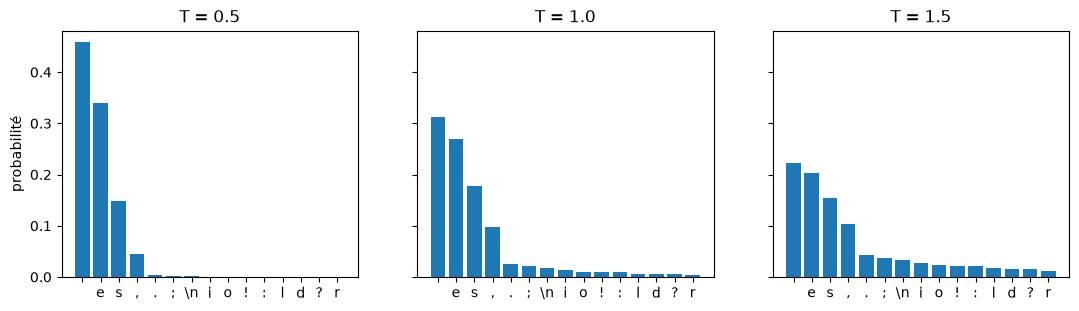

In [8]:
def with_temperature(temperature: float):
    """Renvoie une fonction de tirage à la température donnée."""

    def pick(logits: torch.Tensor) -> torch.Tensor:
        return torch.multinomial(F.softmax(logits / temperature, dim=-1), num_samples=1)

    return pick


order = logits.argsort(descending=True)[:15]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, temperature in zip(axes, [0.5, 1.0, 1.5]):
    p = F.softmax(logits / temperature, dim=-1)[order].cpu()
    ax.bar(range(15), p)
    ax.set_xticks(range(15), [repr(itos[i.item()])[1:-1] for i in order])
    ax.set_title(f"T = {temperature}")
axes[0].set_ylabel("probabilité")

for temperature in [0.5, 1.5]:
    print(f"--- température {temperature} ---")
    print(generate_with(with_temperature(temperature)))

À 0,5, l'orthographe est plus propre mais le texte redevient répétitif. À
1,5, le modèle invente des mots et casse la mise en page. La température
arbitre entre **fiabilité** et **diversité**.

## 6. Le top-k

La température déplace toute la distribution. Le **top-k** attaque
directement le problème du chapitre 4 : on ne garde que les `k` caractères
les plus probables, on met les autres à −∞ (même astuce que le masque de
l'attention), et on tire parmi eux. La **longue traîne** des choix
improbables disparaît, sans toucher à l'ordre des choix restants.

In [9]:
def with_top_k(k: int, temperature: float = 1.0):
    """Renvoie une fonction de tirage limitée aux `k` caractères les plus probables."""

    def pick(logits: torch.Tensor) -> torch.Tensor:
        logits = logits / temperature
        v, _ = torch.topk(logits, min(k, logits.size(-1)))
        logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
        return torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)

    return pick


for k in [1, 5]:
    print(f"--- top-k {k} ---")
    print(generate_with(with_top_k(k)))

--- top-k 1 ---

CORIOLANUS:
Why, then I have been the state of the country.

COMINIUS:
I will not should be so see the sound of the such of the conside
That with the country of the contry of the contraction
That the contraction of the conside of the country.

MENENIUS:
I have been the conside of the conside of the
--- top-k 5 ---
That have all to him fact a brow hath souls this.
With thou shouldst hit be and by thing. How shalt the season
To sad his purposit and that the secely of them,
And wholession shir, show me sometime be sens
The children with more.

CAMILLO:
What is may was and musician what the brokes of time.

LADY 


k = 1 ` est exactement le glouton. `k = 5` garde la variété tout en évitant
les caractères absurdes. En pratique on combine les deux réglages :
température pour la forme de la distribution, top-k pour couper la traîne.

## 7. Pour aller plus loin : le top-p (nucleus)

Défaut du top-k : `k` est fixe. Après `"th"`, deux ou trois suites sont
plausibles ; après une espace, des dizaines. Le **top-p** (Holtzman et al.,
2019) garde le plus petit ensemble de choix dont la probabilité cumulée
dépasse `p`. Le nombre de candidats s'adapte à l'incertitude du modèle.
C'est le réglage par défaut de la plupart des LLM actuels.

In [10]:
def with_top_p(p: float, temperature: float = 1.0):
    """Renvoie une fonction de tirage limitée au noyau de probabilité cumulée `p`."""

    def pick(logits: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits / temperature, dim=-1)
        sorted_probs, sorted_idx = probs.sort(dim=-1, descending=True)
        cumulative = sorted_probs.cumsum(dim=-1)
        # On retire un choix si la masse cumulée AVANT lui dépasse déjà p :
        # le premier choix est toujours gardé.
        sorted_probs[cumulative - sorted_probs > p] = 0.0
        choice = torch.multinomial(sorted_probs / sorted_probs.sum(dim=-1, keepdim=True), num_samples=1)
        return sorted_idx.gather(-1, choice)

    return pick


print("--- top-p 0.9 ---")
print(generate_with(with_top_p(0.9)))

--- top-p 0.9 ---
Lord Servingman:
We shall we swear more had battle,
Here is my lord I madam, my lord. What say your wife
I'll see your counsel'd out of his become
words beast on my case of an all; and I cannot stand
Like an one despect my childly counsensel
Is all changel for his aftidence. Therefore to thy hands;



## 8. Mesurer l'arbitrage

« Plus propre », « plus varié » : mesurons-le. Sur 2 000 caractères générés
par stratégie :

- **mots valides** : la part des mots générés qui existent dans le corpus
  (une mesure grossière de la qualité) ;
- **mots distincts** : la part de mots différents parmi les mots générés
  (une mesure grossière de la diversité ; le glouton qui boucle est très
  bas).

In [11]:
corpus_words = set(re.findall(r"[a-z']+", CORPUS_PATH.read_text(encoding="utf-8").lower()))


def word_stats(generated: str) -> tuple[float, float]:
    """Part de mots valides et part de mots distincts dans un texte généré."""
    gen_words = re.findall(r"[a-z']+", generated.lower())
    valid = sum(w in corpus_words for w in gen_words) / len(gen_words)
    distinct = len(set(gen_words)) / len(gen_words)
    return valid, distinct


strategies = {
    "glouton": greedy,
    "tirage simple (T=1)": sample_plain,
    "température 0.5": with_temperature(0.5),
    "température 1.5": with_temperature(1.5),
    "top-k 5": with_top_k(5),
    "top-k 5, T=0.8": with_top_k(5, temperature=0.8),
    "top-p 0.9": with_top_p(0.9),
}
print(f"{'stratégie':22} {'mots valides':>13} {'mots distincts':>15}")
for name, pick in strategies.items():
    valid, distinct = word_stats(generate_with(pick, n_chars=2_000))
    print(f"{name:22} {valid:>13.1%} {distinct:>15.1%}")

stratégie               mots valides  mots distincts
glouton                        76.5%            7.2%
tirage simple (T=1)            88.3%           62.1%
température 0.5                96.8%           40.9%
température 1.5                60.3%           77.3%
top-k 5                        91.9%           50.6%
top-k 5, T=0.8                 94.7%           44.2%
top-p 0.9                      92.4%           54.5%


Aucune stratégie ne gagne sur les deux colonnes : baisser la température ou
couper la traîne améliore l'orthographe et réduit la diversité, monter la
température fait l'inverse. Le bon réglage dépend de l'usage : un
générateur de noms de sorts n'a pas le même besoin qu'un assistant qui doit
répondre juste.

## 9. La fonction `generate` finale

Température et top-k réunis, dans la forme de nanoGPT. C'est la fonction à
reprendre dans le projet. Retenez la séparation des rôles : le modèle ne
fournit que des logits, **la stratégie de tirage appartient à celui qui
génère**. On peut la changer sans réentraîner quoi que ce soit.

In [12]:
@torch.no_grad()
def generate(idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0,
             top_k: int | None = None) -> torch.Tensor:
    """Prolonge `idx` de `max_new_tokens` tokens.

    Args:
        idx: Contexte de départ, `(B, T)`.
        max_new_tokens: Nombre de tokens à générer.
        temperature: Divise les logits ; < 1 concentre, > 1 aplatit.
        top_k: Si fourni, ne tire que parmi les `top_k` tokens les plus probables.

    Returns:
        Le contexte prolongé, `(B, T + max_new_tokens)`.
    """
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.block_size :]
        logits = model(idx_cond)[:, -1, :] / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float("-inf")
        probs = F.softmax(logits, dim=-1)
        idx = torch.cat((idx, torch.multinomial(probs, num_samples=1)), dim=1)
    return idx


torch.manual_seed(SEED)
start = torch.tensor([encode("JULIET:\n")], device=device)
print(decode(generate(start, 400, temperature=0.8, top_k=10)[0].tolist()))

JULIET:
My gracious lord, that his subdue?

POMPEY:
This maid not for your bridal, I do by thing.

LEONTES:
She seems of mind his purpose of the city most bloody.

CLARENCE:
Therefore his sunns mine articator; blood
Which at he common's.

Second Citizen:
Well, a think, that he's both sins to be time.

Second Servant:
Thou hast services, hath the duke town in blind
His boots on't. I he have the wife, be so
